# Choosing response-surface terms

Explore one model and zone at a time, decide which terms to keep, and record the choice in `config.py`.

**How to use**
1. Set `MODEL` and `ZONE` in the next cell and run all cells (*Run → Run All Cells*).
2. Read the full quadratic, the `drop_one` table and the NCSS search path.
3. Edit `CANDIDATES` in Step 4 and compare them. Put your pick in `"my choice"`.
4. Check the contour plots and residuals for your choice.
5. Copy the printed line from Step 6 into `CONFIG["selected_terms"]` in `config.py`, with your reason.

**Rules**
- Terms: `T` = daily mean temperature, `L` = normalized daily peak load. Write `T^2`, `L^2`, `T*L`.
- Every term set must be **hierarchical** (no `T^2` without `T`, no `T*L` without both `T` and `L`). The engine refuses anything else.
- The **full quadratic stays the model for inference** (tests and intervals). Your choice is the **descriptive** surface you present. p-values on a model picked from the same data are optimistic, whoever picks it.
- Factors are coded to [−1, 1], so coefficients are in coded units. R², fitted values and the search path do not depend on the coding.
- This notebook is never run by the pipeline. `config.py` is the record.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from config import CONFIG
from run_models import MODELS, load_daily, make_surface, selected_terms, zones_for

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
%matplotlib inline

daily = load_daily()
print("Models and zones:")
for m, spec in MODELS.items():
    print(f"  {m:16s} {zones_for(m)}  response={spec['response']} ({spec['transform']})")

Models and zones:
  lvl_zone         ['LZ_HOUSTON', 'LZ_NORTH', 'LZ_SOUTH', 'LZ_WEST']  response=spread_mean (asinh_mad)
  vol_zone         ['LZ_HOUSTON', 'LZ_NORTH', 'LZ_SOUTH', 'LZ_WEST']  response=log_spread_sd (none)
  lvl_sys          ['SYSTEM']  response=spread_mean (asinh_mad)
  vol_sys          ['SYSTEM']  response=log_spread_sd (none)
  lvl_zone_onpeak  ['LZ_HOUSTON', 'LZ_NORTH', 'LZ_SOUTH', 'LZ_WEST']  response=spread_onpeak_mean (asinh_mad)


## Choose the model and zone

In [2]:
MODEL = "vol_zone"     # lvl_zone, vol_zone, lvl_sys, vol_sys, lvl_zone_onpeak
ZONE = "LZ_WEST"       # LZ_HOUSTON, LZ_NORTH, LZ_SOUTH, LZ_WEST, or SYSTEM for *_sys

s, info = make_surface(daily, MODEL, ZONE)
RESPONSE_LABEL = {"asinh_mad": "asinh((spread − median) / MAD)", "none": "log daily spread SD"}[info["transform"]]
BLOCK_AT = {"post_rtcb": 1}   # surfaces are drawn for the post-RTC+B regime (Build Plan 6.6)
display(pd.Series(info, name=f"{MODEL} | {ZONE}").to_frame())

,vol_zone | LZ_WEST
model,vol_zone
zone,LZ_WEST
response,log_spread_sd
transform,none
calendar_days,365
n,361
n_used,361
date_gaps,4
hac_lags,25


## Step 1 — The full quadratic (the model for inference)

`p_approx` uses Newey–West HAC errors and is approximate. The conditional tests ask whether a group of terms, or every term containing a factor, matters *given everything else*. The sequential table splits R² by group (block, linear, quadratic, interaction) and has no p-values.

In [3]:
full = s.full()
print(s.summary(full))
display(s.sequential_ss())
display(s.conditional_tests())

Response y | factors T=temp_mean, L=load_peak_norm | block post_rtcb
n = 361 (dropped 0, date gaps 4) | HAC Newey-West, 25 lags | p-values approximate
terms: T, L, T^2, L^2, T*L
R² = 0.2477   adj R² = 0.2349   AIC = 729.1   BIC = 756.3

           coef_coded       se       t    p_approx
Intercept      3.0183 0.075692  39.877 5.4731e-133
post_rtcb    -0.38631  0.10181 -3.7944  0.00017403
T             -1.3025  0.22945 -5.6765  2.8662e-08
L            -0.62397   0.2129 -2.9309   0.0035998
T^2            1.2269  0.44236  2.7736   0.0058374
L^2           -0.7743  0.64382 -1.2027     0.22991
T*L             1.392  0.74834  1.8601    0.063695

Lack of fit (cubic terms T^3, L^3, T^2*L, T*L^2): F = 0.798, p = 0.5272
Shape: saddle, stationary point {'temp_mean': 72.9117, 'load_peak_norm': 0.8491} (inside data: True)


,df,seq_ss,incremental_r2
source,,,
Regression,6.0,50.4364,0.2477
Block,1.0,1.9432,0.0095
Linear,2.0,15.9199,0.0782
Quadratic,2.0,31.0021,0.1522
Lin x Lin,1.0,1.5712,0.0077
Total Error,354.0,153.2191,0.7523


,terms,q,F,p_approx,last_ss,r2_loss
test,,,,,,
group: Linear,"T, L",2,172.0026,6.4655e-53,42.8349,0.2103
group: Quadratic,"T^2, L^2",2,4.8975,7.9791e-03,8.0813,0.0397
group: Lin x Lin,T*L,1,3.4601,6.3695e-02,1.5712,0.0077
factor: T,"T, T^2, T*L",3,15.3756,2.0041e-09,25.2946,0.1242
factor: L,"L, L^2, T*L",3,14.9187,3.6319e-09,9.7955,0.0481


## Step 2 — What each term costs (`drop_one`)

One row per term in the full quadratic:
- `removable`: hierarchy allows dropping it (`blocked_by` lists the terms that contain it).
- `r2_loss`: R² lost by dropping just this term (NCSS "Last R-Squared").
- `d_aic`, `d_bic`: change if dropped. **Negative means the smaller model is preferred** by that criterion.
- `p_approx`: the term's HAC p-value in the full model.

Removable terms come first, cheapest first.

In [4]:
display(s.drop_one())

,removable,blocked_by,r2_loss,r2_after,adj_r2_after,d_aic,d_bic,p_approx
term,,,,,,,,
L^2,True,,0.0035,0.2441,0.2335,-0.3047,-4.1936,2.2991e-01
T*L,True,,0.0077,0.2399,0.2292,1.6830,-2.2059,6.3695e-02
T^2,True,,0.0273,0.2203,0.2094,10.8715,6.9827,5.8374e-03
L,False,"L^2, T*L",0.0137,0.2340,0.2232,4.4996,0.6108,3.5998e-03
T,False,"T^2, T*L",0.0733,0.1744,0.1628,31.5504,27.6615,2.8662e-08


## Step 3 — The NCSS search, as a guide

Backward elimination: repeatedly drop the removable term that costs the least R², while that loss is below 0.01. This is what NCSS would pick automatically. You do not have to follow it.

In [5]:
search = s.search()
display(search["path"])
print("NCSS search keeps:", search["final_terms"], f"(R² = {search['final_r2']:.4f})")

,step,term,r2_loss,r2_after,removed
0,1,L^2,0.0035,0.2441,True
1,2,T*L,0.0055,0.2386,True
2,3,L,0.0390,0.1996,False


NCSS search keeps: ['T', 'L', 'T^2'] (R² = 0.2386)


## Step 4 — Compare candidate term sets (edit this cell)

Add or change entries. Put your pick under `"my choice"`. `lof_cubic_p` is the lack-of-fit test (cubic terms added): a small value means the surface is missing shape.

In [6]:
CANDIDATES = {
    "full": ["T", "L", "T^2", "L^2", "T*L"],
    "NCSS search": search["final_terms"],
    "no L^2": ["T", "L", "T^2", "T*L"],
    "linear": ["T", "L"],
    "my choice": search["final_terms"],      # <- edit
}
display(s.compare(*CANDIDATES.values(), labels=list(CANDIDATES)))

,terms,n_terms,r2,adj_r2,aic,bic,lof_cubic_p,shape
model,,,,,,,,
full,"T, L, T^2, L^2, T*L",5,0.2477,0.2349,729.0933,756.3155,5.2723e-01,saddle
NCSS search,"T, L, T^2",3,0.2386,0.2300,729.4142,748.8586,9.5266e-02,ridge
no L^2,"T, L, T^2, T*L",4,0.2441,0.2335,728.7886,752.1218,2.8927e-01,ridge
linear,"T, L",2,0.0877,0.0800,792.6800,808.2355,3.3055e-11,no curvature
my choice,"T, L, T^2",3,0.2386,0.2300,729.4142,748.8586,9.5266e-02,ridge


## Step 5 — Inspect your choice

Summary, what each remaining term costs, shape, lack of fit, diagnostics, and the observed-day range of fitted values.

In [7]:
CHOICE = CANDIDATES["my choice"]
fit = s.fit(CHOICE)
print(s.summary(fit))
print()
display(s.drop_one(CHOICE))

diag = s.diagnostics(fit)
print("VIF:", {k: round(v, 2) for k, v in diag["vif"].items()}, "| condition number:", round(diag["condition_number"], 2))
print("Residual autocorrelation lags 1-5:", [round(a, 3) for a in diag["resid_acf_1_5"]],
      "| Ljung-Box p:", round(diag["ljung_box"]["p"], 4), "| Durbin-Watson:", round(diag["durbin_watson"], 3))
print("Highest Cook's distance days:")
display(diag["top_cooks"].to_frame("cooks_distance"))
display(s.fitted_range(fit))

Response y | factors T=temp_mean, L=load_peak_norm | block post_rtcb
n = 361 (dropped 0, date gaps 4) | HAC Newey-West, 25 lags | p-values approximate
terms: T, L, T^2
R² = 0.2386   adj R² = 0.2300   AIC = 729.4   BIC = 748.9

           coef_coded       se       t    p_approx
Intercept      2.9607 0.080862  36.615 9.2787e-123
post_rtcb    -0.42074  0.10232 -4.1119  4.8764e-05
T             -1.0148  0.16278 -6.2345  1.2835e-09
L            -0.77426  0.17319 -4.4706  1.0498e-05
T^2            1.7605  0.25907  6.7954  4.5571e-11

Lack of fit (cubic terms T^3, L^3, T^2*L, T*L^2): F = 1.992, p = 0.0953
Shape: ridge



,removable,blocked_by,r2_loss,r2_after,adj_r2_after,d_aic,d_bic,p_approx
term,,,,,,,,
L,True,,0.0390,0.1996,0.1928,16.0506,12.1617,1.0498e-05
T^2,True,,0.1509,0.0877,0.0800,63.2658,59.3770,4.5571e-11
T,False,T^2,0.1168,0.1218,0.1145,49.5058,45.6169,1.2835e-09


VIF: {'T': 2.51, 'L': 2.36, 'T^2': 2.68} | condition number: 5.36
Residual autocorrelation lags 1-5: [0.327, 0.143, 0.212, 0.133, 0.108] | Ljung-Box p: 0.0 | Durbin-Watson: 1.344
Highest Cook's distance days:


,cooks_distance
local_date,
2026-01-26,0.0755
2026-01-28,0.0562
2026-01-31,0.0425
2025-12-14,0.0294
2026-08-26,0.0290


,fitted,date,temp_mean,load_peak_norm
which,,,,
lowest,2.1156,2026-08-09,84.8625,1.0194
highest,5.8069,2026-01-25,16.1000,0.7266


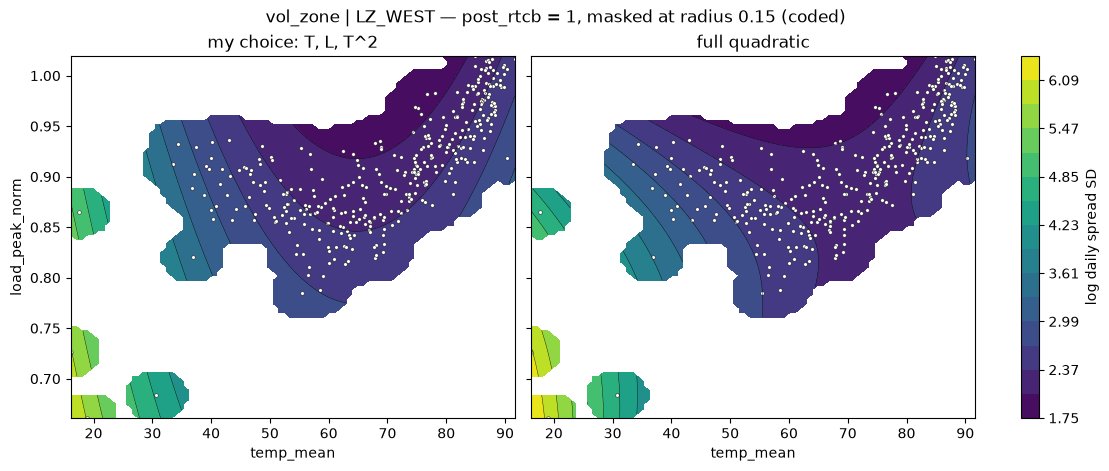

In [8]:
def contour_panels(s, fits, titles, block_values=BLOCK_AT, n=80):
    """Fitted surfaces on one shared color scale, masked to where observed days are
    within the inside-data radius. White dots are observed days."""
    grids = [s.predict_grid(f, n=n, block_values=block_values) for f in fits]
    zs = [np.where(g["inside"], g["z"], np.nan) for g in grids]
    lo, hi = np.nanmin([np.nanmin(z) for z in zs]), np.nanmax([np.nanmax(z) for z in zs])
    levels = np.linspace(lo, hi, 16)
    fig, axes = plt.subplots(1, len(fits), figsize=(5.5 * len(fits), 4.6), sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, g, z, title in zip(axes, grids, zs, titles):
        cf = ax.contourf(g["x"], g["y"], z, levels=levels, cmap="viridis")
        ax.contour(g["x"], g["y"], z, levels=levels, colors="k", linewidths=0.3)
        ax.scatter(s.Xreal[:, 0], s.Xreal[:, 1], s=7, c="white", edgecolors="k", linewidths=0.3)
        ax.set_title(title)
        ax.set_xlabel(g["x_name"])
    axes[0].set_ylabel(grids[0]["y_name"])
    fig.colorbar(cf, ax=axes, label=RESPONSE_LABEL, format="%.2f")
    fig.suptitle(f"{MODEL} | {ZONE} — post_rtcb = 1, masked at radius {s.settings['inside_radius']} (coded)")
    plt.show()

contour_panels(s, [fit, full], [f"my choice: {', '.join(fit.names)}", "full quadratic"])

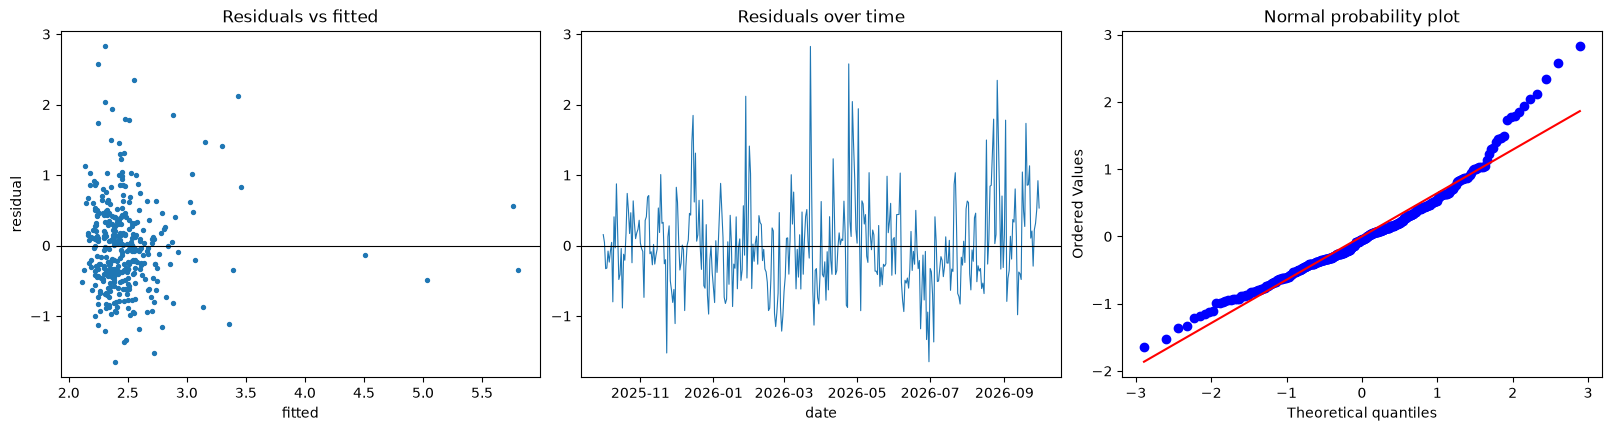

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
axes[0].scatter(fit.fitted, fit.resid, s=8)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
axes[1].plot(fit.resid.index, fit.resid.to_numpy(), lw=0.8)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="date", title="Residuals over time")
stats.probplot(fit.resid.to_numpy(), dist="norm", plot=axes[2])
axes[2].set_title("Normal probability plot")
plt.show()

## Step 6 — Record your choice

Copy the printed line into `CONFIG["selected_terms"]` in `config.py` and replace the `why` text with your reason (for example, the R² loss and AIC change of the dropped terms). The runner refuses term sets that are not hierarchical.

In [10]:
print(f'    "{MODEL}|{ZONE}": {{"terms": {CHOICE!r}, "why": "TODO: your reason"}},')

    "vol_zone|LZ_WEST": {"terms": ['T', 'L', 'T^2'], "why": "TODO: your reason"},


## Progress across all models

In [11]:
rows = []
for m in MODELS:
    for z in zones_for(m):
        sm_, _ = make_surface(daily, m, z)
        f = sm_.full()
        rows.append({"model": m, "zone": z, "n": sm_.n, "full_r2": f.r2,
                     "ncss_search": ", ".join(sm_.search()["final_terms"]),
                     "your_choice": ", ".join(selected_terms(m, z) or []) or "—"})
display(pd.DataFrame(rows).set_index(["model", "zone"]))

n  full_r2          ncss_search your_choice
model           zone                                                     
lvl_zone        LZ_HOUSTON  361   0.0911  T, L, T^2, L^2, T*L           —
                LZ_NORTH    361   0.0491       T, L, L^2, T*L           —
                LZ_SOUTH    361   0.0690       T, L, L^2, T*L           —
                LZ_WEST     361   0.0664            T, L, T*L           —
vol_zone        LZ_HOUSTON  361   0.2467       T, L, L^2, T*L           —
                LZ_NORTH    361   0.2716       T, L, L^2, T*L           —
                LZ_SOUTH    361   0.2063            T, L, T*L           —
                LZ_WEST     361   0.2477            T, L, T^2           —
lvl_sys         SYSTEM      361   0.0620       T, L, L^2, T*L           —
vol_sys         SYSTEM      361   0.2585       T, L, L^2, T*L           —
lvl_zone_onpeak LZ_HOUSTON  257   0.0630               T, T^2           —
                LZ_NORTH    257   0.0302       T, L, L^2, T*L           —
                LZ_SOUTH    257   0.0426       T, L, L^2, T*L           —
                LZ_WEST     257   0.0555       T, L, T^2, T*L           —